<style>
.hero {
  background: linear-gradient(135deg, #0f172a 0%, #1e3a8a 55%, #2563eb 100%);
  color: white;
  padding: 34px 38px;
  border-radius: 14px;
  margin: 4px 0 22px 0;
}
.hero .kicker { font-size: 12px; letter-spacing: 2.4px; text-transform: uppercase; opacity: .82; }
.hero h1 { font-size: 34px; line-height: 1.15; margin: 8px 0 10px 0; color: white; }
.hero p { font-size: 15px; line-height: 1.55; margin: 0; opacity: .93; }
.hero .meta { margin-top: 18px; font-size: 12.5px; opacity: .8; }
.ruta { display: flex; flex-wrap: wrap; gap: 8px; margin: 14px 0 8px 0; }
.ruta span {
  background: #eef2ff; color: #1e3a8a; border-radius: 999px;
  padding: 6px 12px; font-size: 12.5px; font-weight: 600;
}
</style>

<div class="hero">
  <div class="kicker">Build a Large Language Model (From Scratch) · Capítulo 1</div>
  <h1>Entender los grandes modelos de lenguaje</h1>
  <p>Un recorrido interactivo, en español, por las ideas que sostienen a ChatGPT:
  qué es un LLM, cómo se entrena, por qué el transformer lo cambió todo y qué
  vamos a construir en el resto del libro.</p>
  <div class="meta">Cuaderno de estudio · sin GPU · ~75–90 minutos · basado en el capítulo 1 de Sebastian Raschka (Manning, 2024)</div>
</div>

<div class="ruta">
  <span>1 · ¿Qué es un LLM?</span>
  <span>2 · Aplicaciones</span>
  <span>3 · Pretraining y finetuning</span>
  <span>4 · Transformer</span>
  <span>5 · Datos</span>
  <span>6 · GPT por dentro</span>
  <span>7 · El plan</span>
  <span>8 · Autoevaluación</span>
</div>

Este cuaderno no es un resumen para leer de pasada: está pensado para **hacer**. Vas a
entrenar un modelo de lenguaje diminuto, generar texto, construir prompts zero-shot y
few-shot, calcular cuánta memoria ocupa un modelo y comprobar tus ideas con un quiz.

> **Cómo usarlo.** Ejecuta las celdas en orden (`Shift + Enter`). Cuando veas una caja
> **Antes de seguir**, haz una predicción antes de ejecutar. Cuando veas **Experimenta**,
> mueve los controles y compara. Las respuestas están plegadas en los desplegables:
> ábrelos solo después de intentarlo. Las celdas de código son la “cocina”: puedes
> plegarlas con la barra lateral azul si quieres leer solo la explicación.

## Lo que sabrás hacer al terminar

1. Explicar qué significa “grande” en *large language model* y por qué la tarea de
   predecir la siguiente palabra es suficiente para aprender lenguaje.
2. Distinguir **pretraining** de **finetuning**, y **zero-shot** de **few-shot**.
3. Describir el transformer original (encoder + decoder) y por qué GPT usa solo el decoder.
4. Interpretar el papel de la atención y de los grandes corpus de texto.
5. Explicar cómo se genera texto de forma **autorregresiva**, paso a paso.
6. Tener un mapa claro de lo que construiremos en los capítulos 2–7.

<div style="background:#f8fafc;border-left:4px solid #64748b;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🧭 Cómo está organizado cada apartado</b><br>
Una idea → una imagen o una demo → una comprobación. Si algo no queda claro, no sigas:
vuelve a la demo y cambia un parámetro. Aprender LLMs es sobre todo construir intuición.
</div>

In [1]:
# ---------------------------------------------------------------------------
# Entorno: comprobamos versiones y localizamos los recursos del cuaderno.
# No necesitas instalar nada más si ejecutas con el entorno del proyecto.
# ---------------------------------------------------------------------------
import html
import re
import collections
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display
import ipywidgets as widgets

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D0D5DD",
    "axes.labelcolor": "#344054",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.dpi": 110,
})

AZUL = "#2F6FEB"
VERDE = "#1F9D6B"
AMBAR = "#C77800"
GRIS = "#667085"
TINTA = "#1B2430"


def localizar_base():
    """Devuelve la carpeta `notebooks/` sin depender del directorio actual."""
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "assets" / "ch01").exists():
            return c
        if (c / "notebooks" / "assets" / "ch01").exists():
            return c / "notebooks"
    raise FileNotFoundError("No encuentro notebooks/assets/ch01")


BASE = localizar_base()
ASSETS = BASE / "assets" / "ch01"
DATA = BASE / "data"

print(f"Python listo · numpy {np.__version__} · pandas {pd.__version__} · ipywidgets {widgets.__version__}")
print(f"Recursos: {ASSETS.relative_to(BASE)}")
print("✅ Entorno preparado. Puedes ejecutar el cuaderno.")

Python listo · numpy 2.5.4 · pandas 3.1.0 · ipywidgets 8.1.9
Recursos: assets\ch01
✅ Entorno preparado. Puedes ejecutar el cuaderno.


<div style="background:#fff7ed;border-left:4px solid #f59e0b;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>⚙️ Si algo no arranca</b><br>
Desde la raíz del repositorio: <code>uv sync</code> y luego
<code>uv run jupyter lab notebooks/capitulo_01_entender_los_llms.ipynb</code>.
Si abres el cuaderno en VS Code, selecciona el intérprete del entorno <code>.venv</code>.
</div>

---
# 0 · Calentamiento: el juego de la siguiente palabra

Antes de definir nada, hagamos lo que hace un modelo de lenguaje. Lee esta frase:

> «El sol se ocultaba detrás de las montañas y el cielo se tiñó de…»

¿Qué palabra esperas? Probablemente **naranja**, **rojo**, **púrpura** o **azul**.
No necesitaste una regla explícita: tu experiencia con el lenguaje te dio una
distribución de finales plausibles.

Eso es, en esencia, el motor de un LLM:

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:14px 18px;border-radius:6px;margin:16px 0;">
<b>💡 Idea central del capítulo</b><br>
Un LLM es una red neuronal enorme entrenada para <b>predecir el siguiente token</b>.
Todo lo demás —traducir, resumir, programar, conversar— emerge de esa tarea y de la escala.
</div>

La frase “el cielo se tiñó de…” admite varias respuestas. Un LLM no devuelve una única
palabra: devuelve una **probabilidad para cada token posible** y elige una. En este
cuaderno veremos ese mecanismo funcionando de verdad, primero con un modelo de conteo
muy simple y después con la arquitectura que usa GPT.

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✍️ Antes de seguir (30 segundos)</b><br>
Escribe en tu cabeza o en una nota: ¿por qué crees que predecir la siguiente palabra
puede enseñar a un modelo algo tan complejo como la gramática o el razonamiento?
Guarda tu hipótesis; la revisaremos al final del apartado 6.
</div>

---
# 1 · ¿Qué es un LLM?

Un **large language model** es una red neuronal profunda entrenada con cantidades masivas
de texto para **entender, generar y responder** lenguaje humano. La palabra “grande”
se refiere a dos cosas a la vez:

| Dimensión | Qué significa | Ejemplo |
|---|---|---|
| **Parámetros** | Los pesos ajustables de la red; decenas o cientos de miles de millones | GPT-3: 175 000 millones |
| **Datos** | El corpus con el que se entrena; a veces, buena parte del texto público de internet | GPT-3: 300 000 millones de tokens |

Los parámetros son los “botones” que el entrenamiento ajusta. Al principio son ruido;
después de ver mucho texto, codifican patrones de gramática, significado, estilo y
conocimiento factual. Cuando decimos que un LLM “entiende”, queremos decir que **procesa
y genera texto de forma coherente y contextualmente relevante**, no que tenga conciencia
o comprensión humana.

## La jerarquía de la IA

La figura 1.1 sitúa a los LLM dentro del campo más amplio de la inteligencia artificial.
No hace falta memorizar la jerarquía, pero sí tener clara una idea: un LLM es una
aplicación concreta de **deep learning**, no un campo aparte.

![Figura 1.1 · IA, machine learning, deep learning, GenAI y LLM](assets/ch01/fig_1_1_jerarquia_ia.png)

*Figura 1.1 del libro. La IA es el paraguas; el machine learning son algoritmos que
aprenden de datos; el deep learning usa redes neuronales de varias capas; GenAI crea
contenido nuevo; los LLM son un caso particular de GenAI centrado en texto.*

**La diferencia práctica entre ML tradicional y deep learning** está en las características.
En ML tradicional, una persona diseña a mano las variables relevantes (frecuencia de
“gratis”, número de signos de exclamación, mayúsculas…). En deep learning, la red aprende
esas representaciones a partir de los datos. En ambos casos hacen falta ejemplos; la
diferencia es **quién hace la ingeniería de características**.

## “Grande” también significa “mucho hardware”

Una forma de sentir la escala: cada parámetro ocupa memoria. En inferencia con precisión
de 16 bits, un modelo necesita aproximadamente **2 bytes por parámetro** solo para los
pesos. GPT-3, con 175 000 millones de parámetros, ocupa unos **350 GB** antes de contar
activaciones y caché.

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔍 Experimenta</b><br>
Elige un modelo y compara su tamaño con la memoria de un portátil (16 GB) y de una GPU
de datacenter (80 GB). Después mira la fila de “entrenamiento”: entrenar no es solo
guardar los pesos, también hay que guardar gradientes y estados del optimizador.
</div>

| Modelo | Parámetros | Pesos 16 bits | Pesos 8 bits | Pesos 4 bits | Entrenamiento aprox. |
|---|---:|---:|---:|---:|---:|
| GPT-2 small (el del libro) | 124 M | 0,25 GB | 0,12 GB | 0,06 GB | 2 GB |
| GPT-2 XL | 1,5 B | 3 GB | 1,5 GB | 0,75 GB | 24 GB |
| Llama 3.1 8B | 8 B | 16 GB | 8 GB | 4 GB | 128 GB |
| Llama 3.1 70B | 70 B | 140 GB | 70 GB | 35 GB | 1,1 TB |
| GPT-3 | 175 B | 350 GB | 175 GB | 87,5 GB | 2,8 TB |

*Cifras aproximadas: 2 bytes por parámetro en 16 bits, 1 en 8 bits, 0,5 en 4 bits y unos
16 bytes por parámetro para pesos fp32 + gradientes + estados de Adam. Las activaciones
y la caché añaden memoria adicional.*

In [2]:
MODELOS = {
    "GPT-2 small · el del libro (~124 M)": 124e6,
    "GPT-2 XL (1.5 B)": 1.5e9,
    "Llama 3.1 8B": 8e9,
    "Llama 3.1 70B": 70e9,
    "GPT-3 (175 B)": 175e9,
}


def memoria_gb(parametros, bytes_por_parametro):
    return parametros * bytes_por_parametro / 1e9


@widgets.interact(
    nombre=widgets.Dropdown(options=list(MODELOS), value="GPT-3 (175 B)", description="Modelo"),
)
def explorador_memoria(nombre):
    n = MODELOS[nombre]
    fp16 = memoria_gb(n, 2)
    int8 = memoria_gb(n, 1)
    int4 = memoria_gb(n, 0.5)
    entrenamiento = memoria_gb(n, 16)  # pesos fp32 + gradientes + Adam (m, v): ~16 B/param

    fig, ax = plt.subplots(figsize=(9, 3.1))
    etiquetas = ["4 bits", "8 bits", "16 bits", "Entrenamiento (aprox.)"]
    valores = [int4, int8, fp16, entrenamiento]
    colores = ["#A7C4FF", "#5B8DEF", AZUL, AMBAR]
    barras = ax.barh(etiquetas, valores, color=colores, height=0.55)
    ax.set_xscale("log")
    ax.set_xlim(0.05, max(valores) * 4)
    ax.set_xlabel("GB (escala logarítmica)")
    params_txt = f"{n/1e9:,.1f} mil millones" if n >= 1e9 else f"{n/1e6:,.0f} millones"
    ax.set_title(f"{params_txt} de parámetros")
    for barra, valor in zip(barras, valores):
        ax.text(valor * 1.25, barra.get_y() + barra.get_height()/2,
                f"{valor:,.1f} GB", va="center", fontsize=9.5, color=TINTA)
    ax.axvline(16, color=VERDE, linestyle="--", linewidth=1.2)
    ax.text(16*1.08, -0.55, "portátil 16 GB", color=VERDE, fontsize=8.5)
    ax.axvline(80, color="#DC2626", linestyle=":", linewidth=1.2)
    ax.text(80*1.08, -0.55, "A100 80 GB", color="#DC2626", fontsize=8.5)
    ax.set_ylim(-0.8, 3.6)
    plt.tight_layout()
    plt.show()

    display(HTML(f"""
    <div style="background:#f8fafc;border-radius:8px;padding:12px 16px;margin-top:6px;font-size:13.5px">
    <b>{nombre}</b><br>
    Pesos en 16 bits: <b>{fp16:,.1f} GB</b> · en 8 bits: <b>{int8:,.1f} GB</b> ·
    en 4 bits: <b>{int4:,.1f} GB</b><br>
    Entrenamiento con Adam en fp32: <b>{entrenamiento:,.1f} GB</b> solo para estados,
    antes de activaciones. Por eso el preentrenamiento se reparte entre miles de GPU.
    </div>
    """))

interactive(children=(Dropdown(description='Modelo', index=4, options=('GPT-2 small · el del libro (~124 M)', …

<div style="background:#fef2f2;border-left:4px solid #ef4444;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>⚠️ Ojo: tamaño no es lo mismo que capacidad</b><br>
Un modelo más grande no siempre es mejor para tu tarea. Un modelo pequeño bien ajustado
a un dominio concreto puede superar a un modelo generalista enorme. La escala compra
capacidad general; el finetuning compra especialización.
</div>

**Comprueba que lo tienes** <span style="color:#667085">(abre solo después de responder)</span>

<details>
<summary>1. ¿Qué dos cosas miden el “large” de un LLM?</summary>
El número de parámetros y el tamaño/diversidad del corpus de entrenamiento.
</details>

<details>
<summary>2. ¿Un LLM “entiende” como una persona?</summary>
No. Procesa y genera texto que parece coherente y contextualmente adecuado; no tiene
conciencia ni comprensión humana. Es una distinción importante para no antropomorfizar.
</details>

<details>
<summary>3. ¿Dónde encaja un LLM en la jerarquía IA → ML → DL → GenAI?</summary>
Es un tipo de GenAI implementado con deep learning (redes de varias capas), que a su vez
es una rama del machine learning y de la IA.
</details>

---
# 2 · ¿Para qué se usan los LLM?

La razón por la que los LLM se extendieron tan rápido es que **el lenguaje es la interfaz
de casi todo**. Si una tarea se puede formular como “leer texto y producir texto”, un LLM
puede intentarla sin cambiar de arquitectura.

![Figura 1.2 · Una interfaz conversacional convierte instrucciones en texto](assets/ch01/fig_1_2_chatgpt.png)

*Figura 1.2 del libro: el usuario escribe una instrucción y el modelo produce una respuesta.
La interfaz es simple; la magia (y la responsabilidad) está en el modelo.*

Algunas aplicaciones típicas:

| Tarea | Entrada | Salida | Ejemplo |
|---|---|---|---|
| **Traducción** | Texto en un idioma | Texto en otro | “Buenos días” → “Good morning” |
| **Resumen** | Documento largo | Versión breve | Resumen de un contrato |
| **Análisis de sentimiento** | Reseña | Etiqueta | Positivo / negativo / neutro |
| **Generación** | Instrucción o inicio | Texto nuevo | Artículo, cuento, código |
| **Preguntas y respuestas** | Pregunta + contexto | Respuesta | Soporte técnico, medicina, derecho |
| **Asistentes** | Conversación | Respuesta | ChatGPT, Gemini, Copilot |

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 La idea que hay que llevarse</b><br>
El mismo modelo base puede traducir, resumir o clasificar <b>sin reentrenarse</b>:
basta con cambiar el prompt. Eso es posible porque durante el pretraining aprendió
patrones generales del lenguaje, no una tarea única.
</div>

## Detective de tareas

Para cada caso, decide qué tarea principal realiza el modelo. Intenta responder antes de
abrir la solución.

<details>
<summary><b>Caso A.</b> «Resume este informe de 40 páginas en cinco viñetas.»</summary>
<b>Resumen.</b> La entrada es larga y la salida es una versión condensada.
</details>

<details>
<summary><b>Caso B.</b> «Clasifica esta reseña como positiva, negativa o neutra.»</summary>
<b>Clasificación / análisis de sentimiento.</b> La salida pertenece a un conjunto finito de etiquetas.
</details>

<details>
<summary><b>Caso C.</b> «Traduce al inglés: “La reunión empieza a las nueve”.»</summary>
<b>Traducción.</b> La entrada y la salida son el mismo contenido en idiomas distintos.
</details>

<details>
<summary><b>Caso D.</b> «Escribe una función de Python que ordene una lista sin usar sorted().»</summary>
<b>Generación de código.</b> El modelo produce texto nuevo con una estructura formal.
</details>

<details>
<summary><b>Caso E.</b> «Según estos tres documentos, ¿cuál es la política de devoluciones?»</summary>
<b>Preguntas y respuestas sobre un contexto</b> (la base de RAG: recuperar documentos y
pedirle al modelo que responda citándolos).
</details>

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✍️ Ejercicio corto</b><br>
Piensa en una tarea repetitiva de tu trabajo o estudio que implique leer o escribir texto.
Escribe (a) la entrada, (b) la salida deseada y (c) qué podría salir mal. Los LLM son
especialmente útiles cuando la tolerancia al error es alta o cuando hay una persona
revisando; son peligrosos cuando la respuesta se acepta sin verificar.
</div>

---
# 3 · Las dos etapas: pretraining y finetuning

Casi todos los LLM modernos se construyen en dos fases. La primera es cara y general;
la segunda es comparativamente barata y específica.

![Las dos etapas de un LLM](assets/ch01/fig_es_etapas.png)

*Diagrama propio, basado en la figura 1.3 del libro.*

<details>
<summary>Ver la figura 1.3 original del libro</summary>

![Figura 1.3 · Pretraining y finetuning](assets/ch01/fig_1_3_pretraining_finetuning.png)

*Figura 1.3 del libro: preentrenamiento con texto sin etiquetar y finetuning con un
dataset etiquetado más pequeño.*

</details>

## Etapa 1 · Pretraining: aprender el idioma

Se entrena el modelo con **texto sin etiquetar**: web, libros, Wikipedia, artículos,
código. La tarea es siempre la misma: **predecir el siguiente token**. El resultado es un
**modelo base** o *foundation model*, capaz de completar texto y con cierta capacidad de
aprender tareas a partir de unos pocos ejemplos (*few-shot*).

¿De dónde salen las etiquetas si nadie las ha escrito? Del propio texto. Si la frase es
«El gato duerme sobre el sofá», el par de entrenamiento es:

- entrada: `El gato duerme sobre el`
- objetivo: `sofá`

Esto se llama **aprendizaje autosupervisado**: el texto es a la vez la entrada y la
respuesta. No hace falta que un humano etiquete millones de frases.

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 La etiqueta es el siguiente token</b><br>
El modelo no aprende “qué es un gato” de forma explícita: aprende a predecir qué token
suele venir después. La representación interna que construye para acertar termina
capturando gramática, estilo y conocimiento.
</div>

### Mira cómo se fabrica una etiqueta

Mueve la posición y observa el par entrada → objetivo. En el entrenamiento real, el
modelo calcula una predicción en **todas** las posiciones a la vez (con una máscara
causal que impide mirar al futuro); aquí aislamos una para que se vea con claridad.

In [3]:
SENTENCIA = ["El", "gato", "duerme", "sobre", "el", "sofá", "porque", "tiene", "sueño", "."]


def chip(token, fondo, color, borde="transparente", tachado=False):
    estilo = f"background:{fondo};color:{color};border:1px solid {borde};"
    if tachado:
        estilo += "opacity:.35;"
    return (f'<span style="display:inline-block;{estilo}border-radius:6px;'
            f'padding:4px 9px;margin:2px;font-family:ui-monospace,monospace;'
            f'font-size:15px">{html.escape(token)}</span>')


@widgets.interact(
    posicion=widgets.IntSlider(value=5, min=1, max=len(SENTENCIA)-1, step=1,
                               description="Objetivo", continuous_update=True),
)
def fabrica_etiqueta(posicion):
    fila = []
    for i, token in enumerate(SENTENCIA):
        if i < posicion:
            fila.append(chip(token, "#E8F0FE", "#1E3A8A"))
        elif i == posicion:
            fila.append(chip(token, "#FFF4DE", "#92400E", "#F59E0B"))
        else:
            fila.append(chip(token, "#F3F4F6", "#9CA3AF", tachado=True))

    entrada = " ".join(SENTENCIA[:posicion])
    objetivo = SENTENCIA[posicion]
    display(HTML(f"""
    <div style="font-size:15px;margin:4px 0 10px 0">{''.join(fila)}</div>
    <div style="display:flex;gap:14px;flex-wrap:wrap;font-size:13.5px">
      <div style="background:#E8F0FE;border-radius:8px;padding:10px 14px;flex:1;min-width:220px">
        <b>Entrada</b> (lo que ve el modelo)<br>
        <code>{html.escape(entrada)}</code>
      </div>
      <div style="background:#FFF4DE;border-radius:8px;padding:10px 14px;min-width:150px">
        <b>Objetivo</b> (lo que debe predecir)<br>
        <code style="color:#92400E;font-weight:700">{html.escape(objetivo)}</code>
      </div>
    </div>
    """))

interactive(children=(IntSlider(value=5, description='Objetivo', max=9, min=1), Output()), _dom_classes=('widg…

## Etapa 2 · Finetuning: especializar

El modelo base ya “sabe” lenguaje, pero no necesariamente sigue instrucciones ni produce
etiquetas. El **finetuning** lo ajusta con un dataset más pequeño y **etiquetado**. Las dos
variantes que veremos en el libro son:

| Tipo | Datos | Objetivo | Ejemplo |
|---|---|---|---|
| **Instruction tuning** | Pares instrucción → respuesta | Seguir órdenes y conversar | “Traduce esto” → traducción correcta |
| **Clasificación** | Texto → etiqueta | Predecir una categoría | Correo → spam / no spam |

ChatGPT no es solo un modelo base. Es un modelo base sometido a instruction tuning y a
un proceso de **RLHF** (aprendizaje por refuerzo con retroalimentación humana) para alinear
sus respuestas con las preferencias humanas. Veremos ese proceso en el capítulo 7.

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔑 Pretraining vs. finetuning, en una frase</b><br>
<b>Pretraining</b> enseña el idioma con datos masivos y etiquetas gratuitas;
<b>finetuning</b> enseña una tarea con datos pequeños y etiquetas caras.
</div>

### Un caso concreto

Imagina que quieres un asistente para tu empresa. Podrías:

1. Partir de un modelo base abierto (por ejemplo, Llama o GPT-2).
2. Hacer **instruction tuning** con pares de preguntas y respuestas de tu dominio.
3. Evaluar con ejemplos que no estén en el entrenamiento.
4. Desplegarlo en local si los datos son sensibles.

No necesitas entrenar desde cero. Esa es una de las lecciones prácticas del libro:
**reutilizar pesos abiertos** y adaptarlos es mucho más barato que preentrenar.

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✅ Comprueba tu comprensión</b><br>
1. ¿Por qué el pretraining no necesita etiquetas humanas?<br>
2. ¿Qué diferencia hay entre instruction tuning y clasificación?<br>
3. ¿Por qué el finetuning es más barato que el pretraining?<br>
<span style="color:#667085">Respuestas: (1) porque la etiqueta es el siguiente token del propio texto;
(2) el primero aprende a seguir instrucciones, el segundo a asignar una etiqueta;
(3) usa menos datos y parte de un modelo que ya aprendió el lenguaje.</span>
</div>

---
# 4 · El transformer: encoder, decoder y atención

En 2017, el artículo *Attention Is All You Need* introdujo el **transformer**, una
arquitectura de red neuronal pensada para traducir. La idea revolucionaria no fue usar
atención (ya existía), sino **construir toda la arquitectura alrededor de ella**, sin
recurrencia.

El transformer original tiene dos submodules:

- **Encoder**: procesa el texto de entrada y lo convierte en vectores que capturan el
  contexto. Puede mirar toda la frase a la vez.
- **Decoder**: toma esos vectores y genera la salida **token a token**, de izquierda a
  derecha.

En una traducción, el encoder codifica «This is an example» y el decoder produce
«Das ist ein Beispiel». La figura 1.4 muestra el proceso completo, numerado en ocho pasos.

![Figura 1.4 · El transformer original para traducción](assets/ch01/fig_1_4_transformer.png)

*Figura 1.4 del libro. El encoder ve la frase completa; el decoder genera la traducción
una palabra a la vez, realimentando su propia salida.*

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 La asimetría clave</b><br>
El encoder puede mirar toda la entrada. El decoder, en cambio, solo puede mirar lo que
ya generó (y la representación del encoder). Esa restricción es lo que hace que la
generación sea <i>autorregresiva</i>.
</div>

*Dato de escala:* el transformer original apilaba **6 bloques de encoder y 6 de decoder**.
GPT-3 usa **96 capas** y 175 000 millones de parámetros. La misma familia de arquitectura,
otra escala.

## Recorre la traducción paso a paso

Mueve el control y sigue los números de la figura.

In [4]:
PASOS = [
    ("El texto de entrada", "«This is an example» es la frase que queremos traducir. Todavía es texto, no números."),
    ("Preprocesado del encoder", "El texto se divide en tokens y se convierte en vectores numéricos (embeddings)."),
    ("El encoder procesa la entrada", "El encoder mira la frase completa, en ambas direcciones, y construye una representación contextual de cada token."),
    ("Los embeddings llegan al decoder", "La salida del encoder se pasa al decoder como una representación rica del significado de la frase original."),
    ("Salida parcial", "«Das ist ein» es lo que el decoder ya generó. La traducción aún no está completa."),
    ("Preprocesado del decoder", "La salida parcial se tokeniza y se convierte en embeddings para el siguiente paso."),
    ("El decoder genera la siguiente palabra", "Con la representación del encoder y su propia salida parcial, el decoder predice «Beispiel»."),
    ("Traducción completa", "«Das ist ein Beispiel». El proceso se repite hasta que el modelo produce un token de fin de secuencia."),
]


@widgets.interact(
    paso=widgets.IntSlider(value=1, min=1, max=len(PASOS), step=1,
                           description="Paso", continuous_update=False),
)
def recorrer_transformer(paso):
    titulo, texto = PASOS[paso - 1]
    display(Image(filename=str(ASSETS / "fig_1_4_transformer.png"), width=820))
    display(HTML(f"""
    <div style="background:#EEF2FF;border-left:5px solid {AZUL};padding:14px 18px;
                border-radius:6px;margin-top:4px">
      <div style="font-size:12px;letter-spacing:1.5px;color:{AZUL};font-weight:700">
        PASO {paso} DE {len(PASOS)}
      </div>
      <div style="font-size:18px;font-weight:700;color:{TINTA};margin:4px 0 6px 0">
        {titulo}
      </div>
      <div style="font-size:14px;line-height:1.5;color:#344054">{texto}</div>
    </div>
    """))

interactive(children=(IntSlider(value=1, continuous_update=False, description='Paso', max=8, min=1), Output())…

## La pieza que falta: self-attention

El transformer no procesa las palabras como una bolsa desordenada. Para cada token,
calcula **cuánto debe atender a los demás tokens de la secuencia**. Esa ponderación es la
**self-attention**.

Un ejemplo lingüístico clásico:

> «El gato no cruzó la calle porque **estaba** cansado.»

¿Quién estaba cansado? El gato, no la calle. Un modelo que resuelve bien esta frase debe
conectar «cansado» con «gato», aunque estén separados por varias palabras. La atención es
el mecanismo que permite esa conexión de largo alcance.

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔍 Experimenta · atención ilustrativa</b><br>
Elige una palabra y observa a qué otras “presta atención”. Los pesos son una
<i>simulación didáctica</i> construida a mano para mostrar la idea; un transformer real
los aprende durante el entrenamiento (lo implementaremos en el capítulo 3). Abajo tienes
una vista previa con «cansado» y un selector para probar «gato» y «calle».
</div>

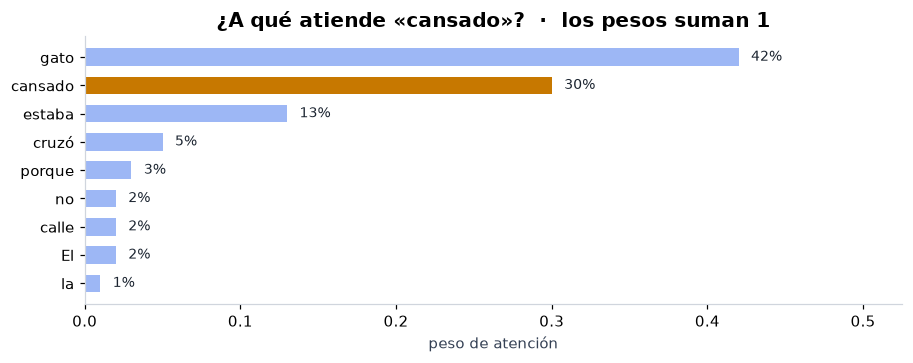

In [5]:
FRASE_ATN = ["El", "gato", "no", "cruzó", "la", "calle", "porque", "estaba", "cansado"]

# Pesos ilustrativos: cada fila dice cuánto mira una palabra al resto.
PESOS_ATN = {
    "gato":    [0.04, 0.38, 0.02, 0.08, 0.02, 0.03, 0.02, 0.16, 0.25],
    "cansado": [0.02, 0.42, 0.02, 0.05, 0.01, 0.02, 0.03, 0.13, 0.30],
    "calle":   [0.05, 0.04, 0.01, 0.30, 0.12, 0.28, 0.02, 0.06, 0.12],
}


def dibujar_atencion(palabra):
    pesos = np.array(PESOS_ATN[palabra], dtype=float)
    pesos = pesos / pesos.sum()
    orden = np.argsort(pesos)
    etiquetas = [FRASE_ATN[i] for i in orden]
    valores = pesos[orden]
    colores = [AMBAR if FRASE_ATN[i] == palabra else "#9DB7F5" for i in orden]

    fig, ax = plt.subplots(figsize=(8.4, 3.4))
    barras = ax.barh(etiquetas, valores, color=colores, height=0.62)
    ax.set_xlim(0, max(valores) * 1.25)
    ax.set_xlabel("peso de atención")
    ax.set_title(f"¿A qué atiende «{palabra}»?  ·  los pesos suman 1")
    for barra, valor in zip(barras, valores):
        ax.text(valor + 0.008, barra.get_y() + barra.get_height()/2,
                f"{valor:.0%}", va="center", fontsize=9, color=TINTA)
    ax.axvline(0, color="#D0D5DD", linewidth=1)
    plt.tight_layout()
    plt.show()

    maxima = FRASE_ATN[int(np.argmax(pesos))]
    display(HTML(f"""
    <div style="font-size:13.5px;color:#344054;margin-top:2px">
    La palabra <b>«{palabra}»</b> dedica más atención a <b>«{maxima}»</b>.
    Esa conexión es la que permite resolver a qué se refiere el adjetivo.
    </div>
    """))


# Vista previa estática: se ve aunque los widgets no estén activos.
dibujar_atencion("cansado")

In [6]:
@widgets.interact(
    palabra=widgets.Dropdown(options=list(PESOS_ATN), value="gato", description="Palabra"),
)
def mapa_atencion(palabra):
    dibujar_atencion(palabra)

interactive(children=(Dropdown(description='Palabra', options=('gato', 'cansado', 'calle'), value='gato'), Out…

### Cómo se calcula la atención (vista de pájaro)

No hace falta implementarlo todavía, pero conviene tener el mapa mental. Cada token se
proyecta en tres vectores:

- **Query (Q)**: “¿qué estoy buscando?”
- **Key (K)**: “¿qué información ofrezco?”
- **Value (V)**: “¿qué contenido aporto si me eligen?”

Para cada token, se compara su query con las keys de todos los tokens (producto escalar),
se normaliza con softmax para obtener pesos que suman 1, y se combinan los values con esos
pesos. El resultado es una representación contextual: la misma palabra puede significar
cosas distintas según su entorno.

<div style="background:#f8fafc;border-left:4px solid #64748b;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🧠 Para profundizar</b><br>
La atención “scaled dot-product” divide por √d para evitar que los productos escalares
crezcan demasiado y saturen el softmax. Veremos los detalles y el código en el capítulo 3,
incluyendo la <b>máscara causal</b> que impide mirar al futuro en un decoder.
</div>

## BERT y GPT: dos formas de usar el transformer

El transformer original tiene encoder y decoder. Dos familias lo adaptaron:

![Figura 1.5 · BERT usa el encoder; GPT usa el decoder](assets/ch01/fig_1_5_bert_vs_gpt.png)

*Figura 1.5 del libro. BERT rellena huecos (predicción de palabras enmascaradas); GPT
completa texto de izquierda a derecha.*

| | **BERT** | **GPT** |
|---|---|---|
| Parte del transformer | Encoder | Decoder |
| Entrenamiento | Enmascarar palabras y predecirlas | Predecir el siguiente token |
| Dirección | Bidireccional (ve toda la frase) | Unidireccional (solo el pasado) |
| Fortalezas | Clasificación, extracción, sentimiento | Generación, diálogo, código |
| Ejemplo real | Detección de contenido tóxico en Twitter | ChatGPT, GPT-3, Llama |

<div style="background:#fef2f2;border-left:4px solid #ef4444;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>⚠️ Transformer ≠ LLM</b><br>
No todos los transformers son LLM: también se usan en visión (ViT) y audio.
Y no todos los LLM son transformers: existen alternativas basadas en RNN y CNN, aunque
buscan sobre todo eficiencia. En este libro, “LLM” significa transformer tipo GPT.
</div>

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✅ Comprueba tu comprensión</b><br>
1. ¿Qué hace el encoder que no hace el decoder?<br>
2. ¿Por qué GPT puede generar texto y BERT es mejor para clasificar?<br>
3. ¿Qué permite la self-attention que no permitía un modelo palabra por palabra?<br>
<span style="color:#667085">(1) procesar toda la entrada y construir representaciones contextuales;
(2) GPT está entrenado para continuar secuencias, BERT para rellenar huecos y mirar en ambas
direcciones; (3) conectar tokens distantes y ponderar su relevancia según el contexto.</span>
</div>

---
# 5 · La escala de los datos

Un LLM no aprende de un libro: aprende de una biblioteca. La tabla 1.1 del libro resume el
corpus de GPT-3. Fíjate en la diversidad: web, libros y Wikipedia, con proporciones muy
distintas.

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 ¿Qué es un token?</b><br>
Una unidad de texto que el modelo lee: puede ser una palabra, parte de una palabra o un
signo de puntuación. En inglés, un token equivale aproximadamente a 0,75 palabras; en
español suele ser algo menos. Lo veremos en detalle en el capítulo 2.
</div>

Dataset,Descripción,Miles de millones de tokens,% del entrenamiento
CommonCrawl (filtrado),Rastreo web,410,60
WebText2,Rastreo web,19,22
Books1,Corpus de libros,12,8
Books2,Corpus de libros,55,8
Wikipedia,Texto de alta calidad,3,3


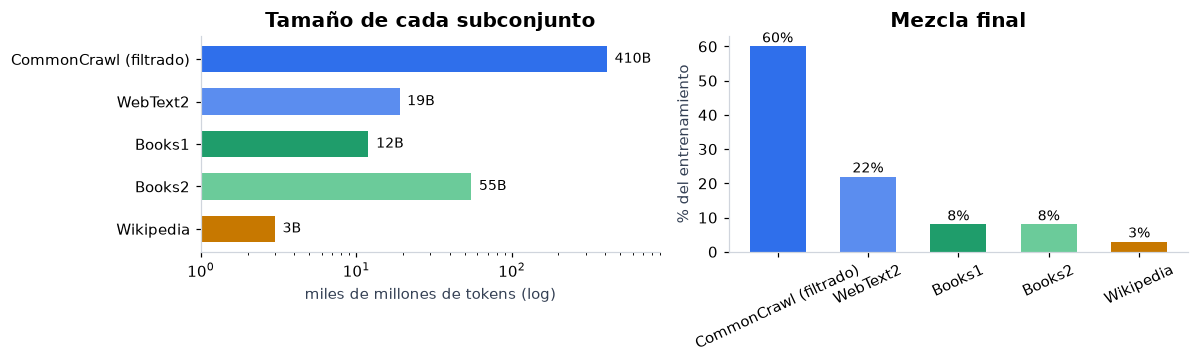

Suma de la columna de tokens: 499B
El libro indica que se entrenó con 300B tokens, no con todos los disponibles.


In [7]:
datos_gpt3 = pd.DataFrame([
    ("CommonCrawl (filtrado)", "Rastreo web", 410, 60),
    ("WebText2", "Rastreo web", 19, 22),
    ("Books1", "Corpus de libros", 12, 8),
    ("Books2", "Corpus de libros", 55, 8),
    ("Wikipedia", "Texto de alta calidad", 3, 3),
], columns=["Dataset", "Descripción", "Miles de millones de tokens", "% del entrenamiento"])

tabla = datos_gpt3.style.hide(axis="index").set_properties(
    **{"text-align": "left", "padding": "8px 12px"}
).set_table_styles([
    {"selector": "th", "props": [("background", "#F2F4F7"), ("text-align", "left"),
                                 ("padding", "8px 12px"), ("font-size", "12.5px")]},
    {"selector": "td", "props": [("font-size", "13px")]},
]).bar(subset=["Miles de millones de tokens"], color="#C7D7FE", vmin=0, vmax=410)

display(tabla)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
colores = ["#2F6FEB", "#5B8DEF", "#1F9D6B", "#6BCB9A", "#C77800"]

ax = axes[0]
ax.barh(datos_gpt3["Dataset"][::-1], datos_gpt3["Miles de millones de tokens"][::-1],
        color=colores[::-1], height=0.62)
ax.set_xscale("log")
ax.set_xlim(1, 900)
ax.set_xlabel("miles de millones de tokens (log)")
ax.set_title("Tamaño de cada subconjunto")
for i, v in enumerate(datos_gpt3["Miles de millones de tokens"][::-1]):
    ax.text(v * 1.12, i, f"{v}B", va="center", fontsize=9)

ax = axes[1]
ax.bar(datos_gpt3["Dataset"], datos_gpt3["% del entrenamiento"], color=colores, width=0.62)
ax.set_ylabel("% del entrenamiento")
ax.set_title("Mezcla final")
ax.tick_params(axis="x", rotation=25)
for i, v in enumerate(datos_gpt3["% del entrenamiento"]):
    ax.text(i, v + 1.2, f"{v}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

print("Suma de la columna de tokens:", f"{datos_gpt3['Miles de millones de tokens'].sum()}B")
print("El libro indica que se entrenó con 300B tokens, no con todos los disponibles.")

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔎 Ojo crítico</b><br>
Las cifras de la tabla suman <b>499B</b>, aunque el texto del libro dice <b>509B</b>
(y aclara que el modelo se entrenó con 300B). Puede ser una errata de la edición.
Lo importante no es memorizar la suma, sino la lección: <b>los números también se auditan</b>.
Cuando leas un paper, comprueba las tablas.
</div>

## ¿Cuánto texto es eso?

Hagamos la escala tangible. El corpus completo de GPT-3 ronda los **300 000 millones de
tokens**; CommonCrawl solo ocupa unos **570 GB**. Un libro de 300 páginas tiene unas
100 000 palabras, es decir, del orden de 130 000 tokens.

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔍 Experimenta</b><br>
Pega un texto tuyo y calcula cuántos tokens aproximados tiene. Después compara con el
corpus de GPT-3 y con la Wikipedia que se usó en su entrenamiento (3B tokens). La
estimación es didáctica: un tokenizador real (BPE) puede dividir las palabras de forma
distinta, sobre todo en español.
</div>

In [8]:
@widgets.interact(
    texto=widgets.Textarea(
        value=("Un modelo de lenguaje aprende a predecir el siguiente token. "
               "Para hacerlo, necesita grandes cantidades de texto y mucha capacidad de cómputo."),
        description="Tu texto",
        layout=widgets.Layout(width="100%", height="110px"),
    ),
)
def estimar_tokens(texto):
    tokens = re.findall(r"\w+|[^\w\s]", texto, flags=re.UNICODE)
    caracteres = len(texto)
    palabras = len(re.findall(r"\w+", texto, flags=re.UNICODE))
    n_tokens = len(tokens)
    pct_gpt3 = 100 * n_tokens / 300e9
    pct_wiki = 100 * n_tokens / 3e9
    paginas = n_tokens / 500

    def tarjeta(valor, etiqueta, color):
        return f"""
        <div style="background:{color}12;border-left:4px solid {color};border-radius:8px;
                    padding:10px 14px;min-width:130px;flex:1">
          <div style="font-size:22px;font-weight:700;color:{color}">{valor}</div>
          <div style="font-size:11.5px;color:#667085">{etiqueta}</div>
        </div>"""

    display(HTML(f"""
    <div style="display:flex;gap:10px;flex-wrap:wrap;margin:8px 0 10px 0">
      {tarjeta(f"{caracteres:,}", "caracteres", GRIS)}
      {tarjeta(f"{palabras:,}", "palabras", GRIS)}
      {tarjeta(f"{n_tokens:,}", "tokens (aprox.)", AZUL)}
      {tarjeta(f"{paginas:,.1f}", "páginas equivalentes", VERDE)}
    </div>
    <div style="font-size:13.5px;color:#344054">
      Es el <b>{pct_gpt3:.10f}%</b> de los 300B tokens de GPT-3 y el
      <b>{pct_wiki:.8f}%</b> de la Wikipedia usada (3B).<br>
      <span style="color:#667085">La escala de un LLM no se aprecia con un párrafo:
      hacen falta millones de documentos.</span>
    </div>
    """))

interactive(children=(Textarea(value='Un modelo de lenguaje aprende a predecir el siguiente token. Para hacerl…

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 ¿Por qué tanta cantidad y diversidad?</b><br>
Porque el modelo debe encontrar patrones que generalicen: sintaxis, semántica, estilos,
hechos, idiomas, código. Un corpus sesgado produce un modelo sesgado. La mezcla de
fuentes y el filtrado de calidad son parte del diseño, no un detalle.
</div>

**Datos y coste.** El preentrenamiento de GPT-3 se estimó en unos **4,6 millones de
dólares** en créditos de computación. Por eso el libro entrena modelos pequeños con fines
educativos y, cuando hace falta, carga pesos ya entrenados. No necesitas reproducir GPT-3
para entender cómo funciona.

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✅ Comprueba tu comprensión</b><br>
1. ¿Qué proporción del corpus de GPT-3 era web?<br>
2. ¿Por qué se entrenó con 300B tokens si había más disponibles?<br>
3. ¿Qué relación hay entre tokens y palabras?<br>
<span style="color:#667085">(1) 60% + 22% = 82% aproximadamente; (2) el libro no lo especifica;
posiblemente por presupuesto de cómputo y calidad de la mezcla; (3) un token es una unidad
más pequeña que una palabra; en inglés, ~0,75 palabras por token.</span>
</div>

---
# 6 · Dentro de GPT: predecir la siguiente palabra

GPT significa **Generative Pretrained Transformer**. Es un transformer que conserva
únicamente el **decoder**, sin encoder. La razón es coherente con su tarea: generar texto
de izquierda a derecha, usando solo el pasado.

![Figura 1.8 · GPT usa solo el decoder y genera iterativamente](assets/ch01/fig_1_8_autoregressive.png)

*Figura 1.8 del libro. En cada iteración, la salida anterior se convierte en parte de la
entrada. Eso es un modelo **autorregresivo**.*

![Figura 1.7 · La única tarea de pretraining: predecir la siguiente palabra](assets/ch01/fig_1_7_next_word.png)

*Figura 1.7 del libro. La frase se divide en tokens y el modelo aprende a rellenar el
siguiente. No hay una etiqueta humana: la etiqueta es el texto mismo.*

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 La paradoja productiva</b><br>
La tarea es trivial para un humano y, sin embargo, obliga al modelo a construir
representaciones de gramática, significado, estilo y mundo. Al predecir millones de
veces, esas representaciones se vuelven útiles para mucho más que completar frases.
</div>

## Construyamos un modelo de lenguaje de verdad (pero diminuto)

Para que la idea no se quede en el aire, vamos a entrenar el modelo de lenguaje más simple
posible: un **modelo de n-gramas** sobre un fragmento de *Don Quijote* (texto de dominio
público). No es una red neuronal, pero la tarea es exactamente la misma: dado un contexto,
predecir el siguiente token.

- Un **unigrama** mira solo la frecuencia de cada palabra.
- Un **bigrama** condiciona la siguiente palabra a la anterior.
- Un **trigrama** usa las dos anteriores.
- Nuestro modelo usará hasta **tres tokens de contexto** (4-gramas), con retroceso a
  contextos más cortos cuando no haya datos.

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔍 Antes de ejecutar</b><br>
Predice: después de «En un lugar de la», ¿qué palabras crees que aparecerán con más
probabilidad en el Quijote? ¿Y después de «El ingenioso hidalgo don»? Ejecuta y compara.
</div>

In [9]:
# ---------------------------------------------------------------------------
# Corpus: un fragmento de Don Quijote (Project Gutenberg, dominio público).
# ---------------------------------------------------------------------------
corpus = (DATA / "quijote_fragmento.txt").read_text(encoding="utf-8")

TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)


def tokenizar(texto):
    """Tokenizador didáctico: palabras y signos de puntuación, en minúsculas."""
    return TOKEN_RE.findall(texto.lower())


TOKENS = tokenizar(corpus)
VOCAB = sorted(set(TOKENS))

print(f"Caracteres del corpus : {len(corpus):,}")
print(f"Tokens               : {len(TOKENS):,}")
print(f"Vocabulario          : {len(VOCAB):,}")
print(f"Ejemplo              : {corpus[:240]!r}...")

Caracteres del corpus : 399,956
Tokens               : 85,568
Vocabulario          : 8,731
Ejemplo              : 'En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mucho\ntiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua,\nrocín flaco y galgo corredor. Una olla de algo más vaca que carnero,\nsalpicón las más noches'...


In [10]:
# ---------------------------------------------------------------------------
# Modelo de n-gramas con retroceso (backoff).
# counts[n][contexto_de_longitud_n-1] -> Counter(siguiente_token)
# ---------------------------------------------------------------------------
MAX_ORDER = 4


def construir_conteos(tokens, max_order=MAX_ORDER):
    counts = {n: collections.defaultdict(collections.Counter) for n in range(1, max_order + 1)}
    for i, token in enumerate(tokens):
        for n in range(1, max_order + 1):
            if i >= n - 1:
                contexto = tuple(tokens[i - n + 1:i])
                counts[n][contexto][token] += 1
    return counts


COUNTS = construir_conteos(TOKENS)


def distribucion(contexto):
    """Devuelve el Counter de siguientes tokens, usando el contexto más largo disponible."""
    contexto = list(contexto)
    for n in range(min(MAX_ORDER - 1, len(contexto)), 0, -1):
        clave = tuple(contexto[-n:])
        if clave in COUNTS[n + 1]:
            return COUNTS[n + 1][clave]
    return COUNTS[1][()]


def top_siguientes(contexto, k=10):
    dist = distribucion(contexto)
    total = sum(dist.values())
    return [(w, c, c / total) for w, c in dist.most_common(k)]


print(f"Contextos distintos de 3 tokens: {len(COUNTS[4]):,}")
print(f"Pares (contexto -> siguiente)  : {sum(len(c) for c in COUNTS[4].values()):,}")

Contextos distintos de 3 tokens: 68,070
Pares (contexto -> siguiente)  : 79,636


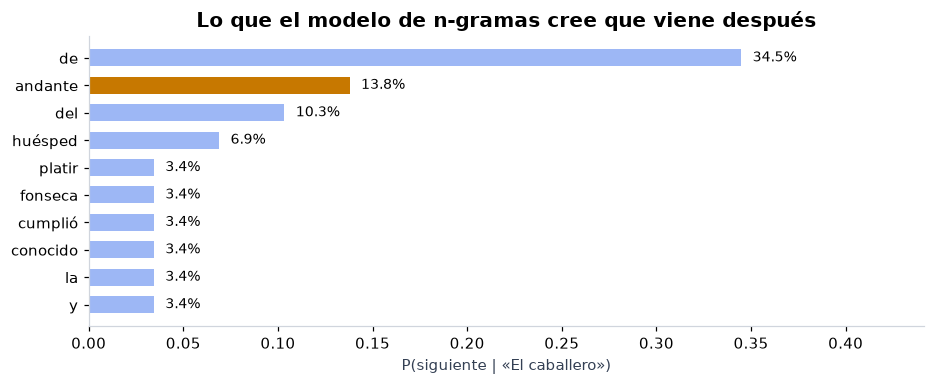

Top 5: de (34.5%), andante (13.8%), del (10.3%), huésped (6.9%), platir (3.4%)


In [11]:
contexto_demo = tokenizar("El caballero")
top = top_siguientes(contexto_demo, 10)

fig, ax = plt.subplots(figsize=(8.6, 3.6))
palabras = [w for w, _, _ in top][::-1]
probs = [p for _, _, p in top][::-1]
colores = [AMBAR if w == "andante" else "#9DB7F5" for w in palabras]
barras = ax.barh(palabras, probs, color=colores, height=0.62)
ax.set_xlim(0, max(probs) * 1.28)
ax.set_xlabel("P(siguiente | «El caballero»)")
ax.set_title("Lo que el modelo de n-gramas cree que viene después")
for barra, prob in zip(barras, probs):
    ax.text(prob + 0.006, barra.get_y() + barra.get_height()/2,
            f"{prob:.1%}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Top 5:", ", ".join(f"{w} ({p:.1%})" for w, _, p in top[:5]))

### Genera tu propio texto

El siguiente widget muestrea tokens del modelo. La **temperatura** controla cuánto se
arriesga: valores bajos eligen casi siempre lo más probable (texto repetitivo y seguro);
valores altos dan más espacio a opciones improbables (más creatividad y más errores).
La **semilla** hace que la generación sea reproducible.

<div style="background:#fffbeb;border-left:4px solid #d97706;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🔍 Experimenta</b><br>
Prueba la misma semilla con temperatura 0,2 / 0,8 / 1,3. Después cambia el comienzo por
«El ingenioso hidalgo don» o «La noche era». Observa dónde el texto se vuelve incoherente.
</div>

In [12]:
CIERRE = set(".,;:!?)]}»”")
APERTURA = set("¿¡([{«“")


def detokenizar(tokens):
    """Une tokens con espaciado razonable para mostrarlos como texto."""
    salida = ""
    pegado = False
    for token in tokens:
        if token in CIERRE:
            salida += token
        elif token in APERTURA:
            salida += (" " if salida else "") + token
            pegado = True
        else:
            salida += ("" if (not salida or pegado) else " ") + token
            pegado = False
    return salida


def muestrear(dist, temperatura=0.8, top_k=40, rng=None):
    rng = rng or np.random.default_rng()
    items = dist.most_common(top_k)
    palabras = [w for w, _ in items]
    conteos = np.array([c for _, c in items], dtype=float)
    if temperatura <= 0.05:
        return palabras[int(np.argmax(conteos))]
    logits = np.log(conteos) / temperatura
    logits -= logits.max()
    probs = np.exp(logits)
    probs /= probs.sum()
    return str(rng.choice(palabras, p=probs))


def generar(prompt, n_tokens=30, temperatura=0.8, top_k=40, semilla=None):
    rng = np.random.default_rng(semilla)
    contexto = tokenizar(prompt)
    generado = []
    pasos = []
    for _ in range(n_tokens):
        dist = distribucion(contexto + generado)
        total = sum(dist.values())
        candidatos = dist.most_common(3)
        elegida = muestrear(dist, temperatura, top_k, rng)
        pasos.append({
            "Contexto reciente": detokenizar((contexto + generado)[-7:]),
            "Top 3 candidatos": " · ".join(f"{w} ({c/total:.0%})" for w, c in candidatos),
            "Elegida": elegida,
        })
        generado.append(elegida)
        if elegida in ".!?":
            break
    return contexto, generado, pasos


@widgets.interact(
    prompt=widgets.Text(value="El caballero", description="Comienzo",
                        layout=widgets.Layout(width="100%")),
    temperatura=widgets.FloatSlider(value=0.8, min=0.1, max=1.5, step=0.1,
                                    description="Temperatura", continuous_update=False),
    n_tokens=widgets.IntSlider(value=30, min=5, max=60, step=5, description="Tokens",
                               continuous_update=False),
    top_k=widgets.IntSlider(value=40, min=5, max=80, step=5, description="Top-k",
                            continuous_update=False),
    semilla=widgets.IntSlider(value=7, min=0, max=99, step=1, description="Semilla",
                              continuous_update=False),
)
def demo_generacion(prompt, temperatura, n_tokens, top_k, semilla):
    contexto, generado, _ = generar(prompt, n_tokens, temperatura, top_k, semilla)
    texto_prompt = detokenizar(contexto)
    texto_gen = detokenizar(generado)
    separador = "" if (not generado or generado[0] in CIERRE) else " "

    display(HTML(f"""
    <div style="background:#0F172A;color:#E5E7EB;border-radius:10px;padding:16px 18px;
                font-family:ui-monospace,SFMono-Regular,Menlo,monospace;font-size:14.5px;
                line-height:1.65">
      <span style="color:#94A3B8">{html.escape(texto_prompt)}</span>{separador}<span
        style="color:#93C5FD;font-weight:600">{html.escape(texto_gen)}</span><span
        style="color:#F59E0B">▌</span>
    </div>
    <div style="font-size:12px;color:#667085;margin-top:6px">
      Modelo de 4-gramas · {n_tokens} tokens · temperatura {temperatura:.1f} ·
      top-k {top_k} · semilla {semilla}
    </div>
    """))

interactive(children=(Text(value='El caballero', description='Comienzo', layout=Layout(width='100%')), FloatSl…

### La generación, paso a paso

Esto es lo que ocurre dentro del bucle. En cada fila, el modelo mira los últimos tokens,
calcula una distribución sobre el vocabulario y elige uno. La elección se añade al
contexto y el proceso se repite.

In [13]:
_, generado_pasos, pasos = generar("El caballero", 8, 0.7, 40, semilla=8)

df_pasos = pd.DataFrame(pasos)
display(df_pasos.style.hide(axis="index").set_properties(
    **{"text-align": "left", "font-size": "12.5px", "padding": "6px 10px"}
).set_table_styles([
    {"selector": "th", "props": [("background", "#F2F4F7"), ("text-align", "left"),
                                 ("padding", "6px 10px"), ("font-size", "12px")]},
]))

display(HTML(f"""
<div style="background:#F8FAFC;border-radius:8px;padding:12px 16px;font-size:14px">
<b>Resultado:</b>
<span style="font-family:ui-monospace,monospace">
{html.escape(detokenizar(tokenizar("El caballero") + generado_pasos))}
</span>
</div>
"""))

Contexto reciente,Top 3 candidatos,Elegida
el caballero,de (34%) · andante (14%) · del (10%),de
el caballero de,la (100%),la
el caballero de la,triste (62%) · ardiente (12%) · mancha (12%),triste
el caballero de la triste,figura (94%) · — (6%),figura
el caballero de la triste figura,", (44%) · — (19%) · . (12%)",;
el caballero de la triste figura;,y (100%),y
caballero de la triste figura; y,"créame (50%) · , (50%)",créame
de la triste figura; y créame,que (100%),que


### La temperatura, en tres versiones

Misma semilla, misma longitud, tres temperaturas. Fíjate en el compromiso entre
coherencia y variedad.

In [14]:
for t in [0.2, 0.7, 1.2]:
    _, gen, _ = generar("En un lugar de la Mancha", 28, t, 40, semilla=11)
    texto = detokenizar(tokenizar("En un lugar de la Mancha") + gen)
    display(HTML(f"""
    <div style="display:flex;gap:12px;align-items:flex-start;margin:6px 0">
      <div style="min-width:82px;font-weight:700;color:{AZUL if t < 0.9 else AMBAR}">
        T = {t}
      </div>
      <div style="font-family:ui-monospace,monospace;font-size:13px;line-height:1.5;
                  background:#F8FAFC;border-radius:6px;padding:8px 12px;flex:1">
        {html.escape(texto)}
      </div>
    </div>
    """))

<div style="background:#fef2f2;border-left:4px solid #ef4444;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>⚠️ Lo que este modelo NO hace</b><br>
El n-grama solo mira tres tokens; no entiende el significado, no generaliza a contextos
nuevos y memoriza frases del corpus. Si le pides una tarea, no la cumplirá. Un LLM
reemplaza los conteos por <b>pesos aprendidos</b> y usa atención para integrar contextos
mucho más largos. La tarea es la misma; la diferencia es la arquitectura y la escala.
</div>

| | Modelo de n-gramas | LLM tipo GPT |
|---|---|---|
| Qué aprende | Frecuencias de secuencias | Representaciones y pesos |
| Contexto | 3 tokens | Miles de tokens |
| Generalización | Limitada a secuencias vistas | Amplia, por composición |
| Parámetros | “Tablas” de conteos | Miles de millones de pesos |
| Entrenamiento | Contar | Descenso de gradiente |

**La conclusión importante:** ya has visto el corazón de un LLM. Lo que falta es cambiar
el contador por una red neuronal y entrenarla. Eso es, literalmente, el resto del libro.

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✍️ Vuelve a tu hipótesis del inicio</b><br>
¿Por qué predecir la siguiente palabra enseña gramática y significado? Porque para acertar
en contextos diversos, el modelo debe aprender regularidades que van mucho más allá de la
palabra inmediata: qué palabras encajan, qué relaciones sintácticas existen, qué hechos
suelen aparecer juntos. La predicción es la excusa; la representación es el premio.
</div>

## Zero-shot y few-shot: aprender sin cambiar los pesos

GPT no solo completa frases. Puede resolver tareas nuevas si se las pides en el prompt.
Hay dos modos:

- **Zero-shot**: solo la instrucción, sin ejemplos.
- **Few-shot**: la instrucción acompañada de unos pocos ejemplos resueltos.

![Figura 1.6 · Completar, zero-shot y few-shot](assets/ch01/fig_1_6_zero_few_shot.png)

*Figura 1.6 del libro. En few-shot, los ejemplos viven dentro del propio input; el modelo
no se reentrena.*

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 Malentendido frecuente</b><br>
En few-shot, el modelo <b>no actualiza sus pesos</b>. Los ejemplos ocupan la ventana de
contexto y condicionan la probabilidad de la siguiente respuesta. Es un aprendizaje
“en contexto”, temporal: si cierras la conversación, desaparece. El finetuning sí cambia
los pesos de forma permanente.
</div>

### Construye un prompt

Elige una tarea y el número de ejemplos. Observa cómo cambia el prompt y cuántos tokens
consume. Con 0 ejemplos tienes zero-shot; con 1 o más, few-shot.

In [15]:
TAREAS = {
    "Traducir al inglés": {
        "instruccion": "Traduce el texto al inglés.",
        "ejemplos": [
            ("Buenos días.", "Good morning."),
            ("¿Dónde está la estación?", "Where is the station?"),
            ("Me gustaría un café.", "I would like a coffee."),
        ],
        "entrada": "¿Dónde está la biblioteca?",
    },
    "Analizar sentimiento": {
        "instruccion": "Clasifica el sentimiento como positivo, negativo o neutro.",
        "ejemplos": [
            ("Me encanta este producto.", "positivo"),
            ("No funciona y llegó tarde.", "negativo"),
            ("Es un producto normal.", "neutro"),
        ],
        "entrada": "El envío fue rápido, pero la caja llegó rota.",
    },
    "Resumir": {
        "instruccion": "Resume el texto en una sola frase.",
        "ejemplos": [
            ("La empresa anunció pérdidas récord y el consejero delegado dimitió.",
             "La empresa atraviesa una crisis tras las pérdidas y la dimisión."),
            ("El equipo ganó el partido en el último minuto y celebró el título.",
             "El equipo se llevó el título con un gol en el último minuto."),
            ("La ciudad invertirá en transporte público durante los próximos cinco años.",
             "La ciudad ampliará el transporte público durante cinco años."),
        ],
        "entrada": "El gobierno presentó un plan para reducir emisiones y crear empleo verde.",
    },
}


@widgets.interact(
    tarea=widgets.Dropdown(options=list(TAREAS), value="Traducir al inglés", description="Tarea"),
    n_ejemplos=widgets.IntSlider(value=2, min=0, max=3, step=1, description="Ejemplos"),
    instruccion=widgets.Checkbox(value=True, description="Incluir instrucción"),
)
def constructor_prompt(tarea, n_ejemplos, instruccion):
    datos = TAREAS[tarea]
    lineas = []
    if instruccion:
        lineas.append(f"Instrucción: {datos['instruccion']}")
    for i, (entrada, salida) in enumerate(datos["ejemplos"][:n_ejemplos], start=1):
        lineas.append(f"\nEjemplo {i}:\nEntrada: {entrada}\nSalida: {salida}")
    lineas.append(f"\nEntrada: {datos['entrada']}\nSalida:")
    prompt = "\n".join(lineas).strip()
    n_tokens = len(tokenizar(prompt))
    modo = "zero-shot" if n_ejemplos == 0 else f"few-shot ({n_ejemplos} ejemplo{'s' if n_ejemplos > 1 else ''})"

    display(HTML(f"""
    <div style="display:flex;justify-content:space-between;align-items:center;margin:6px 0">
      <span style="background:{'#E8F0FE' if n_ejemplos == 0 else '#E6F6EF'};
                   color:{'#1E3A8A' if n_ejemplos == 0 else '#166534'};
                   padding:4px 10px;border-radius:999px;font-size:12px;font-weight:700">
        {modo}
      </span>
      <span style="font-size:12px;color:#667085">{n_tokens} tokens de prompt</span>
    </div>
    <pre style="background:#0F172A;color:#E5E7EB;border-radius:10px;padding:16px;
                font-size:12.5px;line-height:1.55;white-space:pre-wrap">{html.escape(prompt)}</pre>
    <div style="font-size:12.5px;color:#667085">
      Los ejemplos ocupan la ventana de contexto. No cambian los pesos del modelo.
    </div>
    """))

interactive(children=(Dropdown(description='Tarea', options=('Traducir al inglés', 'Analizar sentimiento', 'Re…

## Comportamiento emergente

GPT fue entrenado para predecir texto, no para traducir. Sin embargo, cuando el modelo es
suficientemente grande y ha visto suficientes textos multilingües, la traducción **emerge**
como una capacidad no entrenada explícitamente. Lo mismo ocurre con resumir, corregir
ortografía o resolver problemas sencillos.

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 Emergente ≠ mágico</b><br>
“Emergente” significa que la capacidad no se programó ni se entrenó de forma directa;
aparece como consecuencia de la escala y de la diversidad de datos. Que sea difícil de
predecir no significa que sea inexplicable. Y ojo: muchas capacidades “emergentes”
dependen de cómo se evalúan; la frontera es objeto de debate.
</div>

La consecuencia práctica es enorme: **un solo modelo puede resolver tareas muy distintas
sin un modelo distinto para cada una**. Esa es la diferencia entre el NLP clásico (un
clasificador por tarea) y los LLM generalistas.

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✅ Comprueba tu comprensión</b><br>
1. ¿Por qué GPT es autorregresivo?<br>
2. ¿Qué diferencia hay entre few-shot y finetuning?<br>
3. ¿Qué significa que una capacidad sea emergente?<br>
4. ¿Por qué el modelo de n-gramas no puede seguir instrucciones?<br>
<span style="color:#667085">(1) porque usa su propia salida como entrada en el siguiente paso;
(2) few-shot solo condiciona el contexto, finetuning cambia los pesos; (3) que no fue
entrenada explícitamente y aparece con la escala/datos; (4) porque solo modela secuencias
locales, no representaciones semánticas ni instrucciones.</span>
</div>

---
# 7 · El plan: cómo construiremos un LLM

El libro no empieza con un modelo de 175 000 millones de parámetros. Empieza con los
fundamentos y va añadiendo piezas hasta tener un GPT funcional. La figura 1.9 resume las
tres etapas; el diagrama siguiente las traduce y añade los capítulos.

![El plan del libro en tres etapas](assets/ch01/fig_es_roadmap.png)

*Diagrama propio, basado en la figura 1.9 del libro.*

<details>
<summary>Ver la figura 1.9 original del libro</summary>

![Figura 1.9 · Las tres etapas del libro](assets/ch01/fig_1_9_roadmap.png)

*Figura 1.9 del libro: construir la arquitectura y preparar datos, preentrenar el modelo
base y especializarlo con finetuning.*

</details>

## Qué construiremos, capítulo a capítulo

| Cap. | Pregunta que responde | Lo que te llevas |
|---|---|---|
| **1** | ¿Qué es un LLM y cómo encaja todo? | El mapa mental (este cuaderno) |
| **2** | ¿Cómo convertimos texto en números? | Tokenizador, embeddings, dataloader con ventana deslizante |
| **3** | ¿Cómo mira el modelo el contexto? | Self-attention, atención causal, multi-head |
| **4** | ¿Cómo se ensambla GPT? | Arquitectura GPT completa y generación de texto |
| **5** | ¿Cómo se entrena? | Bucle de entrenamiento, evaluación, modelo base |
| **6** | ¿Cómo se clasifica texto? | Finetuning para clasificación |
| **7** | ¿Cómo sigue instrucciones? | Instruction tuning y alineación |

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>💡 La estrategia del libro</b><br>
Primero se implementa una versión pequeña y comprensible, se entrena con un corpus
modesto y se evalúa. Después se cargan pesos abiertos para saltarse el preentrenamiento
caro. Entender el código es más importante que reproducir el coste de GPT-3.
</div>

**Dos escenarios para ponerlo en perspectiva** (estimaciones de orden de magnitud):

| Escenario | Modelo | Tokens | Hardware | Tiempo | Coste aprox. |
|---|---|---|---:|---:|---:|
| GPT-3 | 175 B | 300 B | A100 a 40 TFLOPS efectivos | ~2,2 M GPU-h | ~4,4 M USD |
| Modelo educativo | 124 M | 1 B | RTX 4090 a 30 TFLOPS efectivos | ~7 GPU-h | ~3,5 USD |

*El segundo escenario usa un precio de 0,5 USD por GPU-hora; el primero, 2 USD. Son
estimaciones, no presupuestos.*

In [16]:
MODELOS_CALC = {
    "Modelo del libro (~124 M)": 124e6,
    "GPT-2 XL (1.5 B)": 1.5e9,
    "Llama 3.1 70B": 70e9,
    "GPT-3 (175 B)": 175e9,
}

GPUS = {
    "CPU (0,3 TFLOPS efectivos)": 0.3,
    "RTX 4090 (30 TFLOPS efectivos)": 30,
    "A100 (40 TFLOPS efectivos)": 40,
    "H100 (150 TFLOPS efectivos)": 150,
}


@widgets.interact(
    modelo=widgets.Dropdown(options=list(MODELOS_CALC), value="GPT-3 (175 B)", description="Modelo"),
    tokens_b=widgets.IntSlider(value=300, min=1, max=1000, step=1,
                               description="Tokens", continuous_update=False),
    gpu=widgets.Dropdown(options=list(GPUS), value="A100 (40 TFLOPS efectivos)", description="Hardware"),
    precio=widgets.FloatSlider(value=2.0, min=0.2, max=10.0, step=0.2,
                               description="$/GPU-h", continuous_update=False),
)
def calculadora_pretraining(modelo, tokens_b, gpu, precio):
    n = MODELOS_CALC[modelo]
    d = tokens_b * 1e9
    flops = 6 * n * d
    tflops = GPUS[gpu]
    horas = flops / (tflops * 1e12 * 3600)
    costo = horas * precio
    anios = horas / 8760
    memoria_train = n * 16 / 1e9

    def tarjeta(valor, etiqueta, color):
        return f"""
        <div style="background:{color}12;border-left:4px solid {color};border-radius:8px;
                    padding:10px 14px;min-width:120px;flex:1">
          <div style="font-size:19px;font-weight:700;color:{color}">{valor}</div>
          <div style="font-size:11px;color:#667085">{etiqueta}</div>
        </div>"""

    display(HTML(f"""
    <div style="display:flex;gap:10px;flex-wrap:wrap;margin:8px 0 10px 0">
      {tarjeta(f"{flops:.2e}", "FLOPs (6 · N · D)", AZUL)}
      {tarjeta(f"{horas:,.0f}", "GPU-horas", VERDE)}
      {tarjeta(f"{anios:,.1f}", "años en 1 GPU", AMBAR)}
      {tarjeta(f"${costo:,.0f}", "coste estimado", "#DC2626")}
    </div>
    <div style="font-size:13px;color:#344054;line-height:1.5">
      Entrenamiento de <b>{modelo}</b> con <b>{tokens_b:,.0f} mil millones</b> de tokens
      en <b>{gpu}</b>.<br>
      Memoria aproximada solo para pesos, gradientes y Adam: <b>{memoria_train:,.0f} GB</b>
      (16 bytes por parámetro; las activaciones añaden más).<br>
      <span style="color:#667085">Regla de oro: FLOPs ≈ 6 · N · D. Es una estimación de
      orden de magnitud; el coste real depende de la utilización, la interconexión y el
      precio de la energía.</span>
    </div>
    """))

interactive(children=(Dropdown(description='Modelo', index=3, options=('Modelo del libro (~124 M)', 'GPT-2 XL …

<div style="background:#fef2f2;border-left:4px solid #ef4444;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>⚠️ No intentes esto en tu portátil</b><br>
Entrenar GPT-3 desde cero requiere miles de GPU durante semanas y millones de dólares.
El libro entrena modelos pequeños para que puedas ejecutar el código y entender cada
pieza. Si quieres un modelo capable sin pagar el pretraining, carga pesos abiertos
(Llama, Mistral, GPT-2) y finetunea.
</div>

## Lo que necesitas para seguir

- **Python** y ganas de escribir código; no hace falta álgebra avanzada para empezar.
- **Un portátil normal** para los capítulos 1–4 y para el finetuning pequeño.
- **GPU opcional** para entrenar más rápido; el código del libro está pensado para ser
  ejecutable en hardware de consumo.
- **Curiosidad crítica**: los LLM producen texto plausible, no necesariamente verdadero.

<div style="background:#f0fdf4;border-left:4px solid #22c55e;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>✅ Antes de pasar al capítulo 2</b><br>
Deberías poder dibujar de memoria el pipeline: texto → tokens → embeddings → transformer →
probabilidades → siguiente token → repetir. Si no te sale, vuelve al apartado 6 y ejecuta
la generación paso a paso.
</div>

---
# 8 · Resumen y autoevaluación

## Las ocho ideas que te llevas

1. **Un LLM es una red neuronal entrenada para predecir el siguiente token.** La escala
   (parámetros y datos) es lo que produce capacidades generales.
2. **“Grande” significa dos cosas:** muchos parámetros y un corpus enorme y diverso.
3. **El pretraining es autosupervisado:** las etiquetas salen del propio texto, sin
   anotadores humanos.
4. **El finetuning especializa** el modelo base con datos etiquetados: instrucciones o
   clases.
5. **El transformer original tiene encoder y decoder.** BERT usa el encoder; GPT usa el
   decoder; ambos son formas distintas de resolver tareas.
6. **La self-attention pondera la relevancia de otros tokens** y permite conectar
   información distante.
7. **GPT genera de forma autorregresiva:** su salida anterior se convierte en entrada
   del siguiente paso.
8. **Zero-shot y few-shot no cambian los pesos:** ponen ejemplos en el contexto. El
   finetuning sí cambia los pesos.

## Glosario mínimo

<details>
<summary><b>LLM (large language model)</b></summary>
Red neuronal profunda entrenada con grandes corpus para procesar y generar lenguaje.
</details>

<details>
<summary><b>Parámetro</b></summary>
Un peso ajustable de la red. El entrenamiento modifica esos valores para reducir el error
de predicción.
</details>

<details>
<summary><b>Token</b></summary>
Unidad de texto que el modelo lee y genera: palabra, fragmento de palabra o signo.
</details>

<details>
<summary><b>Pretraining</b></summary>
Primera fase de entrenamiento, con texto sin etiquetar y la tarea de predecir el siguiente
token. Produce un modelo base o <i>foundation model</i>.
</details>

<details>
<summary><b>Finetuning</b></summary>
Segunda fase, con un dataset más pequeño y etiquetado, para especializar el modelo en una
tarea o dominio.
</details>

<details>
<summary><b>Aprendizaje autosupervisado</b></summary>
Aprendizaje en el que la etiqueta se obtiene del propio dato; en un LLM, el siguiente token.
</details>

<details>
<summary><b>Transformer</b></summary>
Arquitectura de 2017 basada en atención, con módulos encoder y decoder. Base de BERT, GPT
y la mayoría de los LLM actuales.
</details>

<details>
<summary><b>Self-attention</b></summary>
Mecanismo que calcula, para cada token, cuánto debe atender a los demás tokens de la
secuencia.
</details>

<details>
<summary><b>Autorregresivo</b></summary>
Modelo que genera una secuencia paso a paso usando sus propias salidas anteriores como
entrada.
</details>

<details>
<summary><b>Zero-shot / few-shot</b></summary>
Resolver una tarea sin ejemplos / con unos pocos ejemplos incluidos en el prompt, sin
actualizar los pesos.
</details>

<details>
<summary><b>Comportamiento emergente</b></summary>
Capacidad que no se entrenó explícitamente y aparece como consecuencia de la escala y la
diversidad de datos.
</details>

<details>
<summary><b>RLHF</b></summary>
<i>Reinforcement Learning from Human Feedback</i>: ajuste con preferencias humanas para
alinear las respuestas. Se usa, entre otros, en ChatGPT.
</details>

## Pon a prueba lo aprendido

Responde sin mirar las notas. Al pulsar **Corregir** verás tu puntuación y la explicación
de cada respuesta. Si fallas alguna, vuelve al apartado correspondiente.

In [17]:
from IPython.display import clear_output

PREGUNTAS = [
    {
        "pregunta": "¿Qué dos cosas miden el “large” de un large language model?",
        "opciones": ["Solo el número de parámetros",
                     "El número de parámetros y el tamaño del corpus",
                     "La longitud máxima del prompt",
                     "El número de usuarios simultáneos"],
        "correcta": 1,
        "explicacion": "“Grande” se refiere tanto a los parámetros (pesos) como a la cantidad y diversidad de datos de entrenamiento.",
    },
    {
        "pregunta": "¿Cuál es la tarea central del pretraining de GPT?",
        "opciones": ["Clasificar correos como spam",
                     "Traducir sin ejemplos",
                     "Predecir el siguiente token",
                     "Resumir documentos largos"],
        "correcta": 2,
        "explicacion": "GPT se entrena para predecir el siguiente token. Las demás capacidades emergen de esa tarea y de la escala.",
    },
    {
        "pregunta": "¿Por qué el pretraining es autosupervisado?",
        "opciones": ["Porque un humano etiqueta cada frase",
                     "Porque la etiqueta es el propio texto (el siguiente token)",
                     "Porque usa refuerzo con recompensas",
                     "Porque no necesita datos"],
        "correcta": 1,
        "explicacion": "El texto proporciona entrada y objetivo a la vez: la etiqueta es el token que sigue. No hace falta anotación humana.",
    },
    {
        "pregunta": "¿Qué parte del transformer original usa GPT?",
        "opciones": ["El encoder", "El decoder", "Encoder y decoder", "Ninguna"],
        "correcta": 1,
        "explicacion": "GPT es decoder-only: procesa de izquierda a derecha y genera texto de forma autorregresiva.",
    },
    {
        "pregunta": "¿Para qué está especialmente diseñado BERT?",
        "opciones": ["Para generar texto de izquierda a derecha",
                     "Para predecir palabras enmascaradas y clasificar",
                     "Para traducir sin datos",
                     "Para entrenar con RLHF"],
        "correcta": 1,
        "explicacion": "BERT usa el encoder y se entrena rellenando palabras ocultas; destaca en clasificación y extracción.",
    },
    {
        "pregunta": "¿Qué permite el mecanismo de self-attention?",
        "opciones": ["Mirar solo la palabra anterior",
                     "Ponderar la relevancia de otros tokens del contexto",
                     "Reducir el vocabulario",
                     "Evitar el entrenamiento"],
        "correcta": 1,
        "explicacion": "Cada token calcula pesos sobre los demás para construir una representación contextual; puede conectar palabras distantes.",
    },
    {
        "pregunta": "¿Qué es un prompt few-shot?",
        "opciones": ["Entrenar el modelo con pocos datos",
                     "Incluir unos pocos ejemplos resueltos en el prompt",
                     "Usar un modelo con pocos parámetros",
                     "Generar muy pocas palabras"],
        "correcta": 1,
        "explicacion": "Few-shot significa dar ejemplos dentro del contexto. Los pesos no cambian; el modelo aprende “en contexto”.",
    },
    {
        "pregunta": "¿Qué cambia el finetuning a diferencia de few-shot?",
        "opciones": ["El prompt", "Los pesos del modelo", "El tokenizador", "El hardware"],
        "correcta": 1,
        "explicacion": "El finetuning actualiza los pesos con datos etiquetados; few-shot solo condiciona la generación con el contexto.",
    },
    {
        "pregunta": "¿Qué significa que GPT sea autorregresivo?",
        "opciones": ["Que usa su salida anterior como entrada del siguiente paso",
                     "Que se entrena sin etiquetas",
                     "Que genera todos los tokens en paralelo",
                     "Que no necesita contexto"],
        "correcta": 0,
        "explicacion": "Genera un token, lo añade a la secuencia y vuelve a predecir. Ese bucle es la generación autorregresiva.",
    },
    {
        "pregunta": "¿Por qué GPT puede traducir aunque no se entrenó específicamente para ello?",
        "opciones": ["Porque incluye un módulo de traducción",
                     "Por comportamiento emergente a partir de la escala y los datos multilingües",
                     "Porque el prompt cambia los pesos",
                     "Porque usa el encoder de BERT"],
        "correcta": 1,
        "explicacion": "La traducción emerge como capacidad no entrenada explícitamente. Es un ejemplo de comportamiento emergente.",
    },
]

respuestas = []
filas = []
for i, q in enumerate(PREGUNTAS, 1):
    filas.append(widgets.HTML(
        f"<div style='margin:10px 0 2px 0;font-size:14px'><b>{i}.</b> {q['pregunta']}</div>"
    ))
    rb = widgets.RadioButtons(options=q["opciones"], value=None,
                              layout=widgets.Layout(width="100%"))
    respuestas.append(rb)
    filas.append(rb)

boton = widgets.Button(description="Corregir", button_style="primary",
                       layout=widgets.Layout(width="140px"))
reiniciar = widgets.Button(description="Reiniciar",
                           layout=widgets.Layout(width="140px"))
salida = widgets.Output()


def corregir(_):
    aciertos = 0
    bloques = []
    for i, (q, rb) in enumerate(zip(PREGUNTAS, respuestas), 1):
        elegida = rb.value
        correcta = q["opciones"][q["correcta"]]
        ok = elegida == correcta
        aciertos += int(ok)
        color = VERDE if ok else "#DC2626"
        icono = "✅" if ok else "❌"
        detalle = "" if ok else f"<br><span style='color:#667085'>Correcta: <b>{correcta}</b></span>"
        if elegida is None:
            detalle = f"<br><span style='color:#667085'>Sin responder. Correcta: <b>{correcta}</b></span>"
        bloques.append(f"""
        <div style="border-left:3px solid {color};padding:6px 12px;margin:8px 0;
                    background:{color}08;border-radius:4px">
          <b>{icono} {i}. {q['pregunta']}</b>{detalle}
          <br><span style="font-size:12.5px;color:#475467">{q['explicacion']}</span>
        </div>""")

    porcentaje = 100 * aciertos / len(PREGUNTAS)
    mensaje = ("¡Excelente! Puedes pasar al capítulo 2." if porcentaje >= 80 else
               "Buen trabajo, pero revisa los fallos antes de seguir." if porcentaje >= 50 else
               "Vuelve a los apartados correspondientes y repite el quiz.")
    with salida:
        clear_output()
        display(HTML(f"""
        <div style="background:#0F172A;color:white;border-radius:10px;padding:16px 20px;
                    margin:10px 0;font-size:16px">
          Puntuación: <b>{aciertos}/{len(PREGUNTAS)}</b> ({porcentaje:.0f}%) ·
          <span style="color:#93C5FD">{mensaje}</span>
        </div>
        {''.join(bloques)}
        """))


def reiniciar_quiz(_):
    for rb in respuestas:
        rb.value = None
    with salida:
        clear_output()


boton.on_click(corregir)
reiniciar.on_click(reiniciar_quiz)

display(widgets.VBox(filas))
display(widgets.HBox([boton, reiniciar]))
display(salida)

Output()

<div style="background:#f8fafc;border-left:4px solid #64748b;padding:12px 16px;border-radius:6px;margin:14px 0;">
<b>🗒️ Nota</b><br>
Si exportas el cuaderno a HTML estático, los botones del quiz no funcionarán. Abre el
cuaderno en JupyterLab o VS Code con el kernel del proyecto para interactuar.
</div>

## Si puedes explicar esto, dominas el capítulo

- [ ] La diferencia entre parámetros y tokens, y por qué ambos importan.
- [ ] Por qué predecir el siguiente token es una tarea autosupervisada.
- [ ] Qué ocurre en el pretraining y qué ocurre en el finetuning.
- [ ] Por qué GPT usa solo el decoder y BERT solo el encoder.
- [ ] Qué problema resuelve la self-attention.
- [ ] Cómo se genera texto paso a paso.
- [ ] Por qué few-shot no es lo mismo que finetuning.
- [ ] Por qué la escala produce capacidades emergentes.

## Para profundizar

- Vaswani et al., *Attention Is All You Need* (2017): [arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
- Brown et al., *Language Models are Few-Shot Learners* (GPT-3, 2020): [arxiv.org/abs/2005.14165](https://arxiv.org/abs/2005.14165)
- Radford et al., *Improving Language Understanding by Generative Pre-Training* (GPT-1, 2018)
- Devlin et al., *BERT: Pre-training of Deep Bidirectional Transformers* (2018): [arxiv.org/abs/1810.04805](https://arxiv.org/abs/1810.04805)
- Ouyang et al., *Training language models to follow instructions with human feedback* (InstructGPT, 2022): [arxiv.org/abs/2203.02155](https://arxiv.org/abs/2203.02155)
- Hoffmann et al., *Training Compute-Optimal Large Language Models* (Chinchilla, 2022): [arxiv.org/abs/2203.15556](https://arxiv.org/abs/2203.15556)

## Siguiente capítulo

En el **capítulo 2** convertiremos texto en números: tokenización, vocabulario, tokens
especiales, embeddings y ventanas deslizantes. Es el primer código que se reutiliza en el
resto del libro.

<div style="background:#eef2ff;border-left:4px solid #2F6FEB;padding:14px 18px;border-radius:6px;margin:18px 0;">
<b>🚀 Cuando quieras continuar</b><br>
Pide el cuaderno del capítulo 2 y seguimos desde aquí. El objetivo es que cada capítulo
produzca una pieza ejecutable del modelo, no solo apuntes.
</div>

---

<div style="font-size:11.5px;color:#667085;line-height:1.6">
<b>Créditos y uso de las figuras.</b> Este cuaderno es material de estudio personal basado
en el capítulo 1 de <i>Build a Large Language Model (From Scratch)</i> de Sebastian Raschka
(Manning, 2024). Las figuras 1.1–1.9 provienen del libro y se incluyen únicamente como
apoyo educativo; todos los derechos pertenecen a Manning Publications y al autor. Los
diagramas en español son elaboración propia. El fragmento de <i>Don Quijote</i> procede de
Project Gutenberg (dominio público).<br><br>
<b>Limitación.</b> Las estimaciones de tokens, memoria y coste son didácticas y de orden de
magnitud; no sustituyen una medición sobre el hardware real.
</div>